# Open the Thai GeoTIFFs and patches

Shows what is inside `data/thailand/<area>/` (raw rasters) and `data/patches/` (64 x 64 patches).
`read()` and `stretch()` are the same as in `src/check_thailand.py`; they are repeated here because
importing that file switches matplotlib to a backend that does not draw in a notebook.

Run the cells from top to bottom. Change `AREA`, `ROW`, `COL`, `SIZE` or `CLASS` to look elsewhere.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))   # lets "import config" find src/config.py

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

import config as c

In [2]:
def read(area, product):
    """Read one raster of an area: (bands, H, W) array, transform, crs and band names."""
    with rasterio.open(c.thai_path(area, f"{product}.tif")) as src:
        return src.read(), src.transform, src.crs, list(src.descriptions)


def stretch(rgb):
    """Scale reflectance to 0-1 between the 2nd and 98th percentile for display."""
    lo, hi = np.percentile(rgb[rgb > 0], (2, 98))
    return np.clip((rgb - lo) / (hi - lo), 0, 1)


def composite(img, names, bands):
    """Pick three bands by name and return a displayable (H, W, 3) image."""
    idx = [names.index(b) for b in bands]
    return stretch(img[idx].astype("float32").transpose(1, 2, 0))


codes = sorted(c.WORLDCOVER_CLASSES)
cmap = ListedColormap([c.WORLDCOVER_CLASSES[k][1] for k in codes])
norm = BoundaryNorm(codes + [codes[-1] + 1], cmap.N)
legend = [Patch(color=c.WORLDCOVER_CLASSES[k][1], label=c.WORLDCOVER_CLASSES[k][0]) for k in codes]

## 1. One whole area (raw rasters)

In [3]:
AREA = "bangkok"   # bangkok, suphanburi, nan or kanchanaburi

l2a, transform, crs, bands = read(AREA, "S2_L2A")
wc, _, _, _ = read(AREA, "worldcover")
obs, _, _, _ = read(AREA, "clearobs")

print(f"{AREA}: {l2a.shape[2]} x {l2a.shape[1]} px, {l2a.shape[0]} bands, {crs}, dtype {l2a.dtype}")
print("bands:", bands)
print("pixel size (m):", transform.a)
print("upper-left corner:", (transform.c, transform.f))

bangkok: 3072 x 3072 px, 12 bands, EPSG:32647, dtype uint16
bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12']
pixel size (m): 10.0
upper-left corner: (652200.0, 1541520.0)


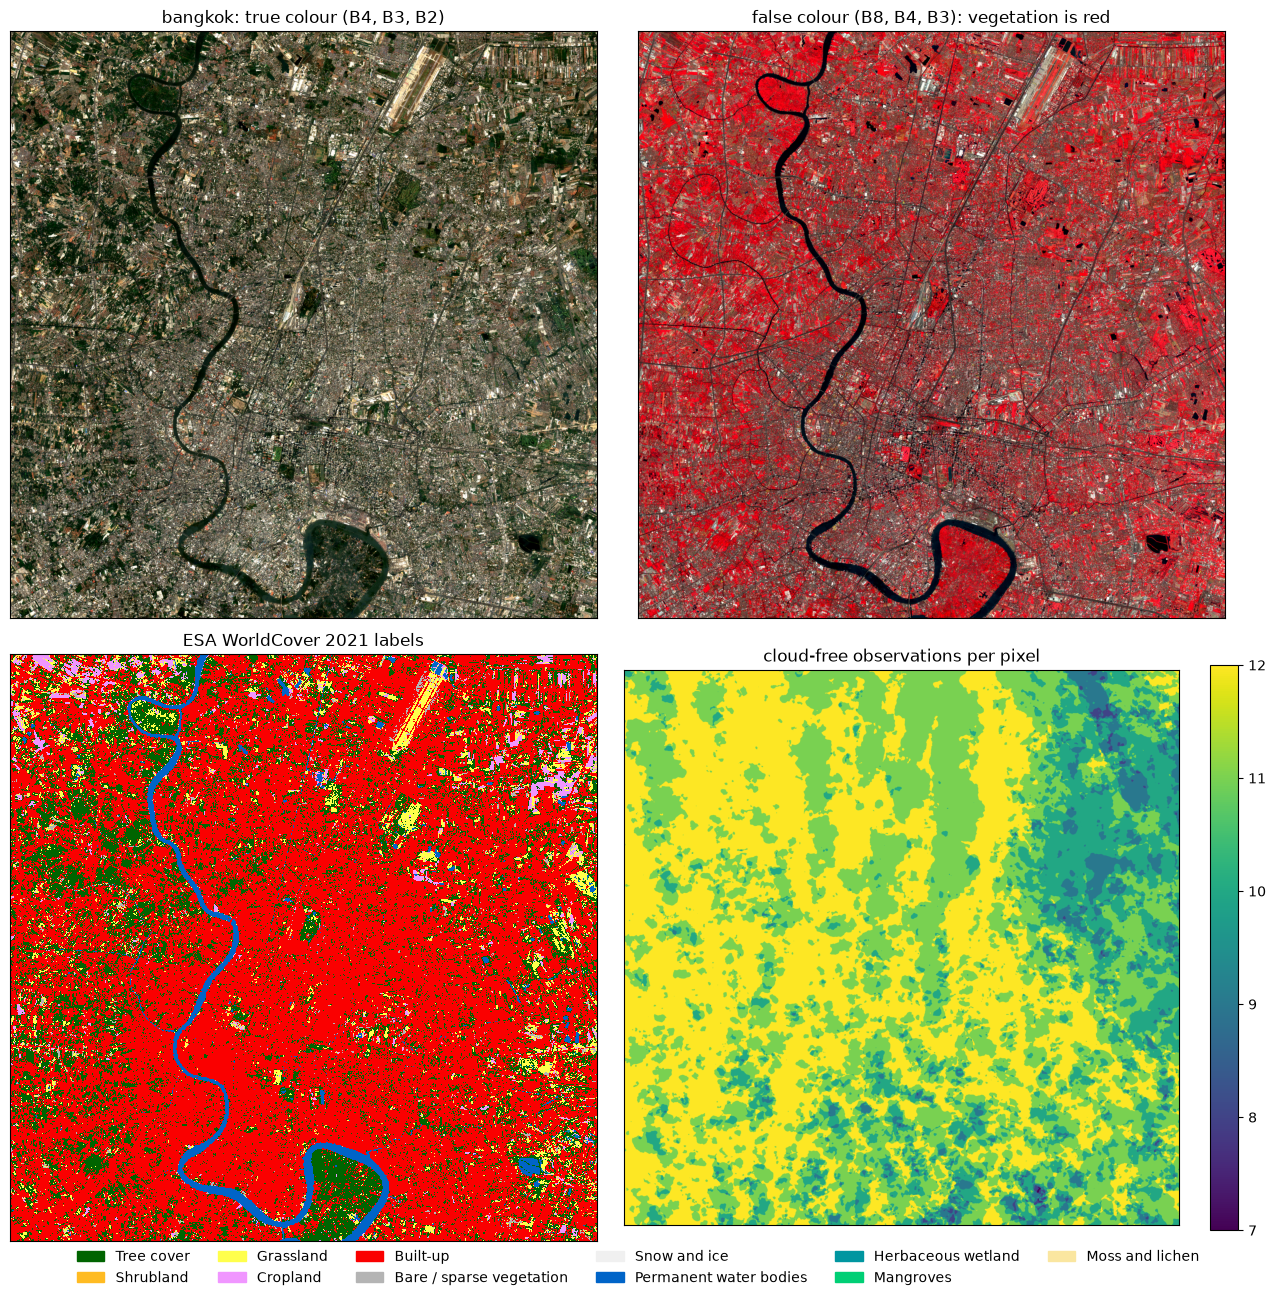

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
axes[0, 0].imshow(composite(l2a, bands, ("B4", "B3", "B2")))
axes[0, 0].set_title(f"{AREA}: true colour (B4, B3, B2)")
axes[0, 1].imshow(composite(l2a, bands, ("B8", "B4", "B3")))
axes[0, 1].set_title("false colour (B8, B4, B3): vegetation is red")
axes[1, 0].imshow(wc[0], cmap=cmap, norm=norm, interpolation="nearest")
axes[1, 0].set_title("ESA WorldCover 2021 labels")
im = axes[1, 1].imshow(obs[0], cmap="viridis")
axes[1, 1].set_title("cloud-free observations per pixel")
fig.colorbar(im, ax=axes[1, 1], fraction=0.046)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.legend(handles=legend, loc="lower center", ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 2. Zoom into a window

The areas are 3072 x 3072 px. Pick a top-left corner (`ROW`, `COL`) and a size to see single pixels.
One 64 x 64 patch is `ROW = 64 * r`, `COL = 64 * c`, `SIZE = 64`.

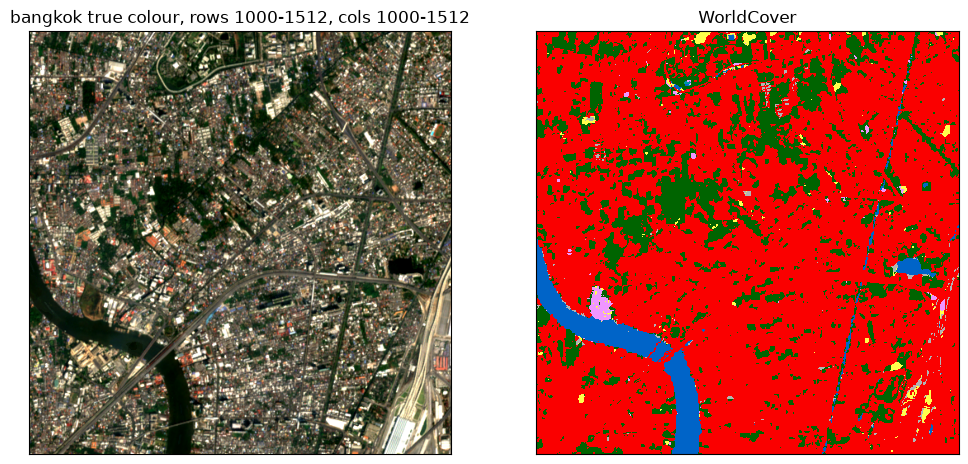

In [5]:
ROW, COL, SIZE = 1000, 1000, 512

sl = (slice(ROW, ROW + SIZE), slice(COL, COL + SIZE))
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(composite(l2a[:, sl[0], sl[1]], bands, ("B4", "B3", "B2")))
axes[0].set_title(f"{AREA} true colour, rows {ROW}-{ROW + SIZE}, cols {COL}-{COL + SIZE}")
axes[1].imshow(wc[0][sl], cmap=cmap, norm=norm, interpolation="nearest")
axes[1].set_title("WorldCover")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

## 3. L1C against L2A

The Thai test set uses L1C (same processing level as EuroSAT); L2A is the comparison. Mean value of every band:

In [6]:
l1c, _, _, bands_l1c = read(AREA, "S2_L1C")
means = pd.DataFrame({
    "L1C": {b: l1c[i].mean() for i, b in enumerate(bands_l1c)},
    "L2A": {b: l2a[i].mean() for i, b in enumerate(bands)},
}).round(0)
means

,L1C,L2A
B1,1765.0,879.0
B2,1509.0,998.0
B3,1350.0,1160.0
B4,1259.0,1172.0
B5,1334.0,1450.0
B6,1790.0,1920.0
B7,2062.0,2128.0
B8,1925.0,2125.0
B8A,2238.0,2270.0
B9,361.0,2272.0


## 4. Patches (after `make_thai_patches.py`)

`thailand_X_L1C.npy` is opened with `mmap_mode="r"`, so the 900 MB file is not loaded into memory.
The CSV is read with `keep_default_na=False`, otherwise the area name `nan` (Nan province) becomes an empty value.

In [7]:
X = np.load(c.PATCH_DIR / "thailand_X_L1C.npy", mmap_mode="r")
y = np.load(c.PATCH_DIR / "thailand_y.npy")
table = pd.read_csv(c.PATCH_DIR / "thailand_patches.csv", keep_default_na=False)

print("images:", X.shape, X.dtype, " labels:", y.shape)
print("usable (pure) patches:", int(table["pure"].sum()), "of", len(table))
pd.crosstab(table.loc[table["pure"], "label"], table.loc[table["pure"], "area"])

images: (9216, 12, 64, 64) uint16  labels: (9216,)
usable (pure) patches: 3023 of 9216


area,bangkok,kanchanaburi,nan,suphanburi
label,,,,
built-up,280,0,0,1
crop,0,1,13,521
forest,5,1088,683,0
water,0,431,0,0


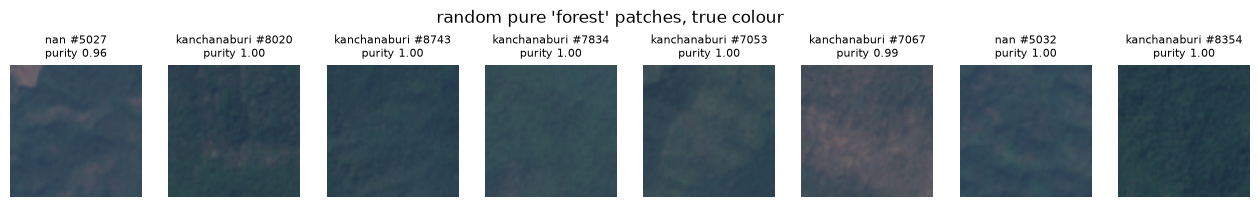

In [8]:
CLASS = "forest"   # forest, crop, built-up or water
N = 8

ids = table.index[table["pure"] & (table["label"] == CLASS)].to_numpy()
chosen = np.random.default_rng(c.SEED).choice(ids, size=min(N, len(ids)), replace=False)
rgb = [c.BANDS.index(b) for b in ("B4", "B3", "B2")]

fig, axes = plt.subplots(1, len(chosen), figsize=(2 * len(chosen), 2.5), squeeze=False)
for ax, i in zip(axes[0], chosen):
    ax.imshow(np.clip(X[i][rgb].transpose(1, 2, 0).astype("float32") / 3000, 0, 1))
    ax.set_title(f"{table.loc[i, 'area']} #{i}\npurity {table.loc[i, 'purity']:.2f}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"random pure '{CLASS}' patches, true colour")
plt.show()